# Explore the Data

**Goal:** understand the training data well enough to decide how to prepare it and which models to try. Every number here comes from the **training set only** (`train_set.parquet`, 2,418 sightings). The test set is not opened in this notebook.

**Reminder of the decision we are supporting.** A trip costs **\$200** and a missed diseased squirrel costs **\$1,000**, so an agent is worth sending once the probability of disease is above **20%**. So the question for every column is: *does it help tell the squirrels above 20% apart from the ones below?*

**How to read the rate tables.** With only about 300 diseased squirrels in training, many groups are small. Every rate table shows the number of sightings and a **95% range** for the rate. The column `above 20%?` is:
- **yes** if the whole range is above 20%
- **no** if the whole range is below 20%
- **unclear** if the range crosses 20%, meaning there are too few sightings to tell

| Checklist step | Section |
|---|---|
| 1. Copy the data, downsample if needed | 1 |
| 2. Study each attribute | 2 |
| 3. Identify the target | 3 |
| 4. Visualize the data | 4 |
| 5. Study the correlations | 5 |
| 6. Study how you would solve the problem manually | 6 |
| 7. Identify promising transformations | 7 |
| 8. Identify extra data that would be useful | 8 |
| 9. Document what you have learned | 9 |

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 60)

TARGET = "diseased"
COST_MISS, COST_TRIP = 1000, 200           # client notes
BREAK_EVEN_P = COST_TRIP / COST_MISS       # 20%
SEED = 42

TRAIN_PATH = Path("train_set.parquet")     # written by the Get the Data step in Nutosis.ipynb
LANDMARKS_PATH = Path("data_cache/landmarks.parquet")

In [2]:
# Helpers used throughout the notebook

def wilson(k, n, z=1.96):
    # 95% range for a rate of k successes out of n (Wilson interval, works well for small groups)
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.divide(k, n, out=np.zeros_like(k), where=n > 0)
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(center - half, 0, 1), np.clip(center + half, 0, 1)


def rate_by(df, col, min_n=1):
    # Share of diseased squirrels in each group of `col`, with a 95% range and a verdict vs. the 20% break-even
    g = df.groupby(col, dropna=False)[TARGET].agg(sightings="size", diseased="sum")
    g = g[g["sightings"] >= min_n].copy()
    g["share diseased"] = g["diseased"] / g["sightings"]
    g["95% low"], g["95% high"] = wilson(g["diseased"], g["sightings"])
    g["above 20%?"] = np.where(g["95% low"] > BREAK_EVEN_P, "yes",
                               np.where(g["95% high"] < BREAK_EVEN_P, "no", "unclear"))
    return g.sort_values("share diseased", ascending=False).round(3)


def total_cost(trips, missed):
    return COST_TRIP * trips + COST_MISS * missed


def rule_cost(name, sent, y):
    # Cost of a "send an agent when `sent` is True" rule on the rows of y
    sent, y = np.asarray(sent, bool), np.asarray(y, bool)
    trips, caught, missed = int(sent.sum()), int((sent & y).sum()), int((~sent & y).sum())
    return {"rule": name, "trips": trips, "diseased caught": caught, "diseased missed": missed,
            "precision": round(caught / trips, 3) if trips else np.nan,
            "recall": round(caught / y.sum(), 3), "total cost ($)": total_cost(trips, missed)}

## 1. Copy the data for exploration

We load the training set and work on a **copy** (`explore`), so nothing done here can change the saved file. The training set is small (about 2,400 rows), so there is **no need to downsample**.

In [3]:
train = pd.read_parquet(TRAIN_PATH)
explore = train.copy()
explore[TARGET] = explore[TARGET].astype(bool)

print(f"Training set: {explore.shape[0]:,} rows x {explore.shape[1]} columns")
print(f"Diseased: {int(explore[TARGET].sum())} ({explore[TARGET].mean():.1%})")
print(f"Dates: {explore['date'].min():%b %d} to {explore['date'].max():%b %d, %Y} ({explore['date'].nunique()} days)")
print(f"Memory: {explore.memory_usage(deep=True).sum() / 1e6:.1f} MB, so no downsampling needed")

Training set: 2,418 rows x 49 columns
Diseased: 303 (12.5%)
Dates: Oct 06 to Oct 20, 2018 (11 days)
Memory: 1.2 MB, so no downsampling needed


## 2. Study each attribute and its characteristics

For each column: name, type, % missing, number of distinct values, most common values, and what role it can play. The **role** is our judgment, written in the `ROLE` dictionary below so it is easy to change:

| Role | Meaning |
|---|---|
| `target` | What we predict |
| `feature` | Candidate input for the model |
| `free text` | Notes typed by volunteers. Not usable as-is, but keywords may be (see section 5) |
| `identifier` | Names a row, carries no general pattern. Never a feature |
| `duplicate` | Same information as another column |
| `people only` | Built in the Get Data step for animal control to read, not for the model |

In [4]:
ROLE = {
    "diseased": "target",
    "Unique Squirrel ID": "identifier",
    "Lat/Long": "duplicate (of X and Y)",
    "Date": "duplicate (of date)",
    "Combination of Primary and Highlight Color": "duplicate (of the two color columns)",
    "Color notes": "free text", "Other Activities": "free text", "Other Interactions": "free text",
    "Specific Location": "free text",
    "geo_nearest_place_dist_m": "people only", "geo_nearest_place_direction": "people only",
    "geo_where_text": "people only",
    "date": "feature (time, only 11 days: use with care)",
}


def role_of(col):
    return ROLE.get(col, "feature")


def kind_of(col):
    s = explore[col]
    if pd.api.types.is_bool_dtype(s):
        return "boolean"
    if pd.api.types.is_datetime64_any_dtype(s):
        return "date"
    if pd.api.types.is_numeric_dtype(s):
        return "numeric (discrete)" if s.nunique() <= 15 else "numeric (continuous)"
    if role_of(col) in ("free text", "people only", "identifier"):
        return "text"
    return "categorical (many values)" if s.nunique() > 60 else "categorical"


def top_values(s, k=3):
    vc = s.value_counts(dropna=True).head(k)
    return "; ".join(f"{v} ({n})" for v, n in vc.items())


profile = pd.DataFrame({
    "type": [kind_of(c) for c in explore],
    "% missing": (explore.isna().mean() * 100).round(1),
    "distinct": explore.nunique(),
    "most common (count)": [top_values(explore[c]) for c in explore],
    "role": [role_of(c) for c in explore],
}, index=explore.columns)
profile

,type,% missing,distinct,most common (count),role
X,numeric (continuous),0.0,2418,-73.95613449379 (1); -73.96885746911 (1); -73.9742811484...,feature
Y,numeric (continuous),0.0,2418,40.79408238841 (1); 40.78378252084 (1); 40.77553361908 (1),feature
Unique Squirrel ID,text,0.0,2415,7D-PM-1010-01 (2); 40B-AM-1019-06 (2); 4C-PM-1010-05 (2),identifier
Hectare,categorical (many values),0.0,329,14D (27); 14E (24); 01B (24),feature
Shift,categorical,0.0,2,PM (1349); AM (1069),feature
Date,numeric (discrete),0.0,11,10132018 (357); 10072018 (313); 10142018 (288),duplicate (of date)
Hectare Squirrel Number,numeric (continuous),0.0,22,1 (479); 2 (442); 3 (351),feature
Age,categorical,4.0,3,Adult (2053); Juvenile (264); ? (4),feature
Primary Fur Color,categorical,1.7,3,Gray (1982); Cinnamon (311); Black (83),feature
Highlight Fur Color,categorical,35.4,10,"Cinnamon (621); White (471); Cinnamon, White (221)",feature


In [5]:
# Numeric columns: range and shape of the distribution
num_cols = [c for c in explore if profile.loc[c, "type"].startswith("numeric") and role_of(c).startswith("feature")]


def shape_label(s):
    s = s.dropna()
    if s.nunique() <= 2:
        return "two values"
    sk = s.skew()
    if abs(sk) < 0.5:
        return "roughly symmetric"
    return ("right-skewed (long tail of high values)" if sk > 0 else "left-skewed (long tail of low values)") + \
        (", strongly" if abs(sk) > 1 else "")


num_summary = explore[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]]
num_summary["skew"] = explore[num_cols].skew()
num_summary["share of zeros"] = (explore[num_cols] == 0).mean()
num_summary["distribution"] = [shape_label(explore[c]) for c in num_cols]
num_summary.round(2)

,min,25%,50%,75%,max,skew,share of zeros,distribution
X,-73.98,-73.97,-73.97,-73.96,-73.95,0.23,0.00,roughly symmetric
Y,40.76,40.77,40.78,40.79,40.80,0.31,0.00,roughly symmetric
Hectare Squirrel Number,1.00,2.00,3.00,6.00,23.00,1.50,0.00,"right-skewed (long tail of high values), strongly"
geo_dist_water_m,2.50,210.15,342.10,456.82,739.10,0.09,0.00,roughly symmetric
geo_dist_hill_m,42.00,684.22,2240.35,3022.62,3734.80,-0.19,0.00,roughly symmetric
geo_dist_green_m,29.70,417.42,720.05,1222.45,2239.60,0.71,0.00,right-skewed (long tail of high values)
wx_prcp_mm,0.00,0.00,0.00,0.00,10.90,2.78,0.75,"right-skewed (long tail of high values), strongly"
wx_tmax_c,10.00,14.40,20.00,23.30,26.70,0.13,0.00,roughly symmetric
wx_tmin_c,5.60,7.80,10.60,17.80,21.70,0.25,0.00,roughly symmetric
wx_wind_ms,0.50,1.10,1.20,1.80,2.60,0.63,0.00,right-skewed (long tail of high values)


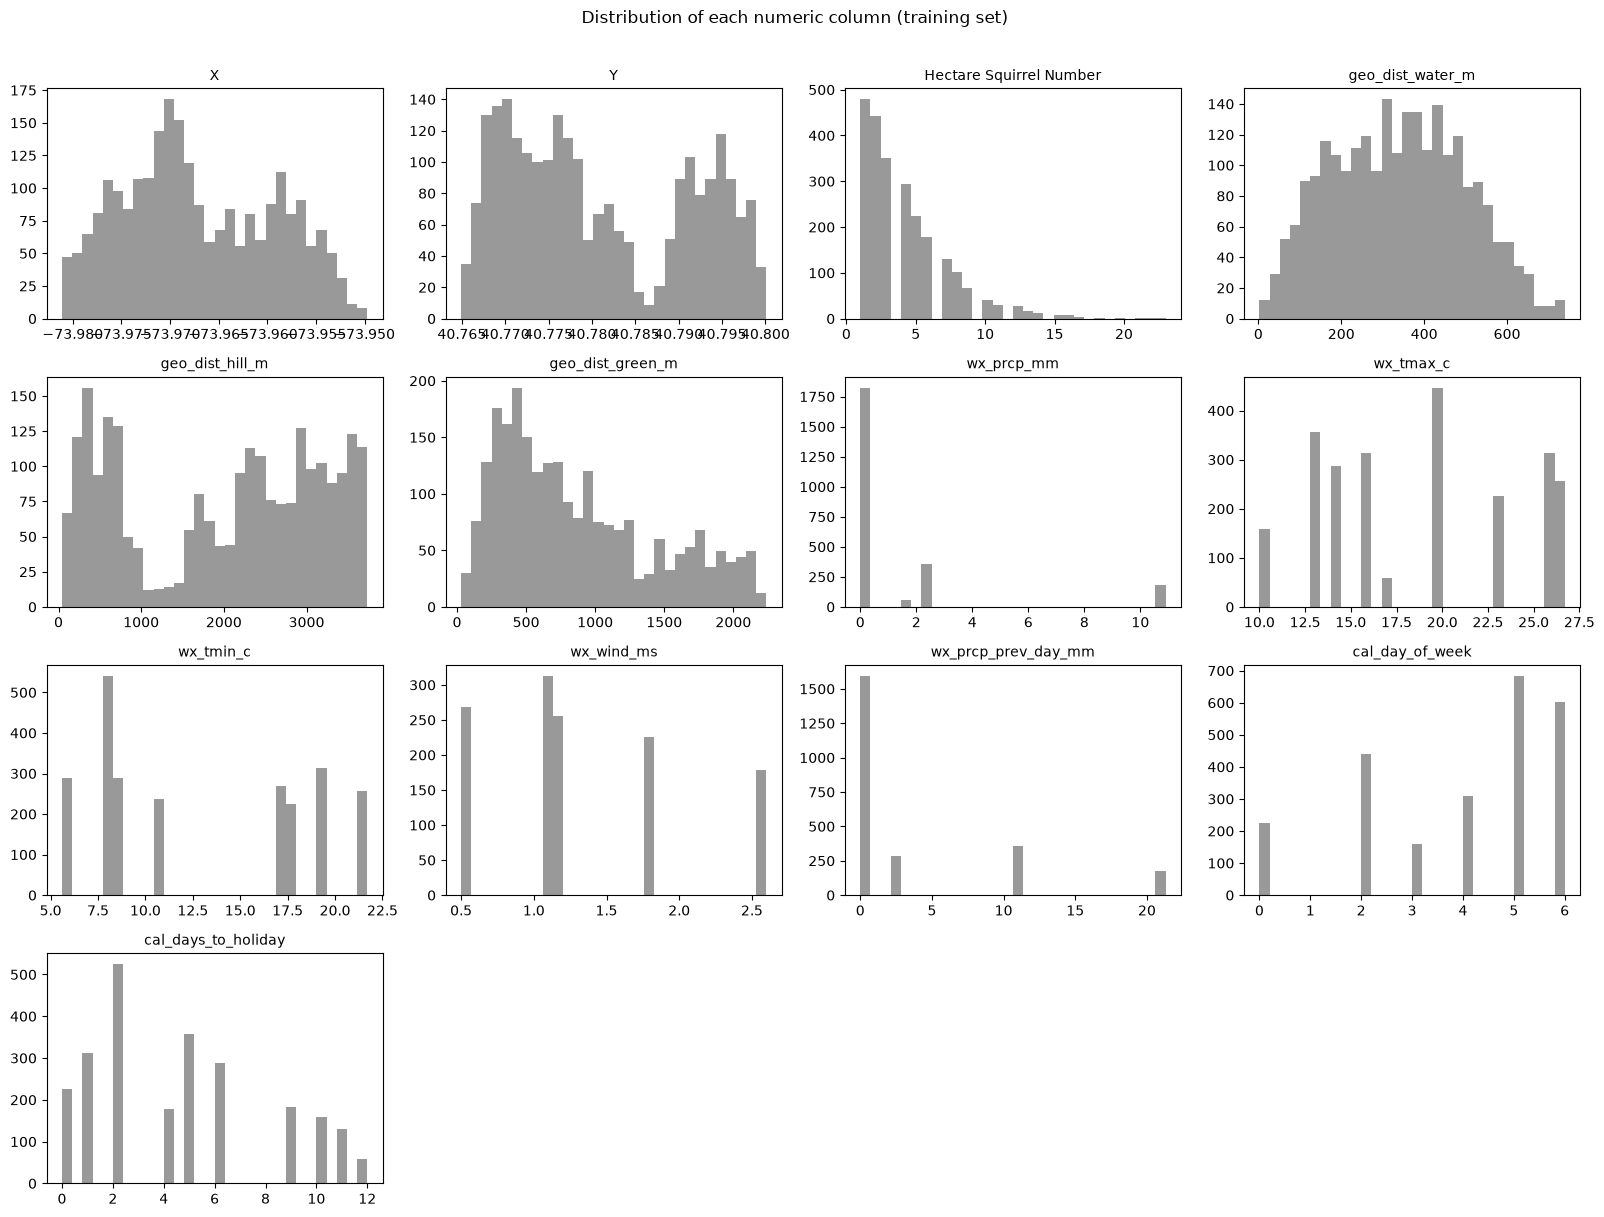

In [6]:
fig, axes = plt.subplots(int(np.ceil(len(num_cols) / 4)), 4, figsize=(16, 3 * int(np.ceil(len(num_cols) / 4))))
for ax, c in zip(axes.flat, num_cols):
    explore[c].dropna().plot.hist(bins=30, ax=ax, color="0.6")
    ax.set_title(c, fontsize=10)
    ax.set_ylabel("")
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle("Distribution of each numeric column (training set)", y=1.01)
fig.tight_layout()
plt.show()

### Noise and data-quality checks

The census was filled in by volunteers, so we look for the kinds of noise that are likely: unknown values, mixed types in one column, contradictions between columns, and columns that should agree with each other but do not.

In [7]:
checks = {}

# Age: '?' means the volunteer could not tell
if "Age" in explore:
    checks["Age values"] = explore["Age"].value_counts(dropna=False).to_dict()

# Above Ground Sighter Measurement: should be a height in feet, but also holds 'FALSE' (= on the ground)
if "Above Ground Sighter Measurement" in explore:
    agm = explore["Above Ground Sighter Measurement"].astype("string")
    agm_num = pd.to_numeric(agm, errors="coerce")
    checks["Above ground: numeric heights"] = int(agm_num.notna().sum())
    checks["Above ground: 'FALSE'"] = int((agm.str.upper() == "FALSE").sum())
    checks["Above ground: missing"] = int(agm.isna().sum())
    checks["Above ground: other text"] = sorted(agm[agm_num.isna() & agm.notna() & (agm.str.upper() != "FALSE")].unique())[:10]
    checks["Above ground: max height (ft)"] = float(agm_num.max())
    # does the height agree with Location?
    if "Location" in explore:
        checks["Above ground: height > 0 but Location = Ground Plane"] = int(((agm_num > 0) & (explore["Location"] == "Ground Plane")).sum())

# Highlight fur can list several colors in one cell, e.g. "Cinnamon, White"
if "Highlight Fur Color" in explore:
    checks["Highlight fur: cells with more than one color"] = int(explore["Highlight Fur Color"].fillna("").str.contains(",").sum())

# Lat/Long should match X and Y
if "Lat/Long" in explore:
    ll = explore["Lat/Long"].astype("string").str.extract(r"(-?\d+\.\d+)\s+(-?\d+\.\d+)").astype(float)
    checks["Lat/Long disagrees with X/Y (rows)"] = int(((ll[0] - explore["X"]).abs().gt(1e-6) | (ll[1] - explore["Y"]).abs().gt(1e-6)).sum())

# The ID is built from hectare, shift, date and number, e.g. 37F-PM-1014-03
id_parts = explore["Unique Squirrel ID"].astype("string").str.extract(r"^(\w+)-(AM|PM)-(\d{4})-(\d+)$")
checks["IDs not matching hectare-shift-MMDD-number"] = int(id_parts[0].isna().sum())
checks["IDs whose hectare differs from the Hectare column"] = int((id_parts[0] != explore["Hectare"].astype("string")).sum())
checks["Rows sharing an ID with another row"] = int(explore["Unique Squirrel ID"].duplicated(keep=False).sum())

# Behaviors: rows with no behavior ticked, and contradictory ones
BEHAVIORS = [c for c in ["Running", "Chasing", "Climbing", "Eating", "Foraging", "Kuks", "Quaas", "Moans",
                         "Tail flags", "Tail twitches", "Approaches", "Indifferent", "Runs from"] if c in explore]
checks["Rows with no behavior ticked"] = int((explore[BEHAVIORS].sum(axis=1) == 0).sum())
if {"Approaches", "Runs from"} <= set(explore):
    checks["Approaches AND Runs from"] = int((explore["Approaches"] & explore["Runs from"]).sum())
if {"Indifferent", "Runs from"} <= set(explore):
    checks["Indifferent AND Runs from"] = int((explore["Indifferent"] & explore["Runs from"]).sum())

# Exact duplicate rows (ignoring the ID)
checks["Exact duplicate rows (ignoring ID)"] = int(explore.drop(columns=["Unique Squirrel ID"]).duplicated().sum())

for k, v in checks.items():
    print(f"{k:55s} {v}")

Age values                                              {'Adult': 2053, 'Juvenile': 264, nan: 97, '?': 4}
Above ground: numeric heights                           619
Above ground: 'FALSE'                                   1706
Above ground: missing                                   93
Above ground: other text                                []
Above ground: max height (ft)                           100.0
Above ground: height > 0 but Location = Ground Plane    0
Highlight fur: cells with more than one color           316
Lat/Long disagrees with X/Y (rows)                      0
IDs not matching hectare-shift-MMDD-number              0
IDs whose hectare differs from the Hectare column       736
Rows sharing an ID with another row                     6
Rows with no behavior ticked                            46
Approaches AND Runs from                                16
Indifferent AND Runs from                               29
Exact duplicate rows (ignoring ID)                      0


### What each census column means

From the 2018 Central Park Squirrel Census data dictionary, so everyone on the team reads the columns the same way:

| Column | Meaning |
|---|---|
| `X`, `Y` | Longitude and latitude of the sighting |
| `Hectare` | Grid cell of the park: a row number 01–42 (south to north) and a column letter A–I (west to east) |
| `Shift` | AM or PM |
| `Hectare Squirrel Number` | Order of this squirrel among those counted in that hectare on that shift |
| `Age` | Adult, Juvenile, or `?` (could not tell) |
| `Primary Fur Color`, `Highlight Fur Color` | Main fur color, and secondary colors (can list several) |
| `Location` | Ground Plane or Above Ground |
| `Above Ground Sighter Measurement` | Height in feet if above ground, `FALSE` if on the ground |
| `Running` … `Foraging` | What the squirrel was doing |
| `Kuks`, `Quaas`, `Moans` | Sounds (alarm calls) |
| `Tail flags`, `Tail twitches` | Tail signals (alarm / agitation) |
| `Approaches`, `Indifferent`, `Runs from` | Reaction to the person reporting |
| `Other Activities`, `Other Interactions`, `Color notes`, `Specific Location` | Free text |

## 3. Identify the target attribute

The target is **`diseased`** (True / False), built in the Get Data step by matching `Unique Squirrel ID` to `diseased.csv`.

- This is **supervised binary classification**, but what we need out of the model is a **probability**, because the decision is "send when the probability is above 20%".
- About **1 in 8** training sightings is diseased, so the classes are imbalanced. Accuracy is a poor measure here: predicting "healthy" for everyone is about 87% accurate and catches nobody.
- **Assumption carried over from the Frame step:** squirrels not in `diseased.csv` are treated as healthy. If some were never tested, a few "healthy" labels are wrong. That would make every rate in this notebook a slight underestimate.

In [8]:
y = explore[TARGET]
print(y.value_counts().rename(index={True: "diseased", False: "healthy"}).to_string())
print(f"\nShare diseased: {y.mean():.1%}")
print(f"Accuracy of always predicting 'healthy': {1 - y.mean():.1%} (catches 0 diseased squirrels)")

diseased
healthy     2115
diseased     303

Share diseased: 12.5%
Accuracy of always predicting 'healthy': 87.5% (catches 0 diseased squirrels)


## 4. Visualize the data

### 4a. Where are the diseased squirrels?

If the disease spreads from squirrel to squirrel, diseased sightings should **cluster** in parts of the park rather than being scattered evenly.

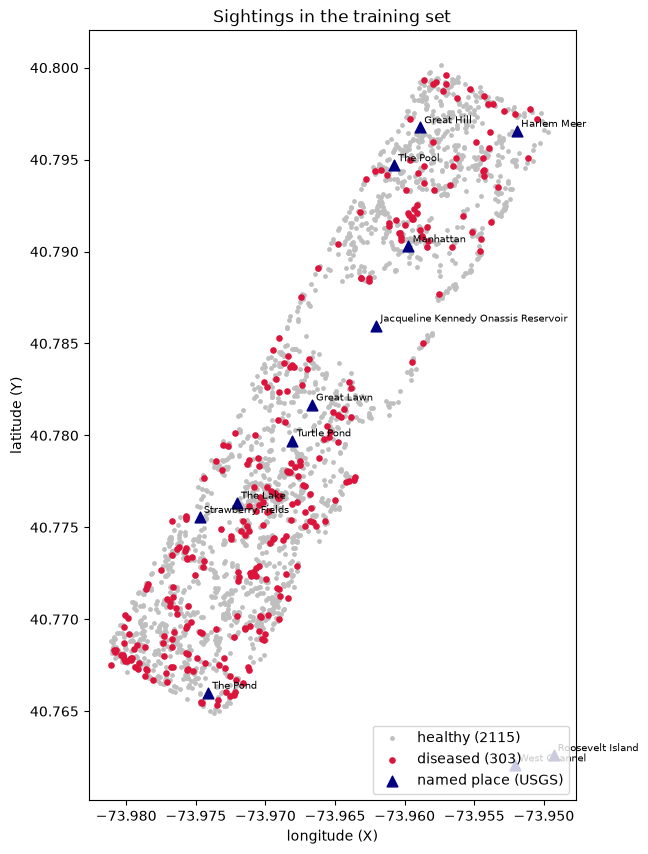

In [9]:
fig, ax = plt.subplots(figsize=(7, 10))
healthy, sick = explore[~explore[TARGET]], explore[explore[TARGET]]
ax.scatter(healthy["X"], healthy["Y"], s=6, c="0.75", label=f"healthy ({len(healthy)})")
ax.scatter(sick["X"], sick["Y"], s=14, c="crimson", label=f"diseased ({len(sick)})")

if LANDMARKS_PATH.exists():                                     # named places from the Get Data step, if present
    lm = pd.read_parquet(LANDMARKS_PATH)
    ax.scatter(lm["lon"], lm["lat"], marker="^", s=60, c="navy", label="named place (USGS)")
    for _, r in lm.iterrows():
        ax.annotate(r["name"], (r["lon"], r["lat"]), fontsize=7, xytext=(3, 3), textcoords="offset points")

ax.set_aspect(1 / np.cos(np.radians(explore["Y"].mean())))     # so the park is not stretched
ax.set_xlabel("longitude (X)")
ax.set_ylabel("latitude (Y)")
ax.set_title("Sightings in the training set")
ax.legend(loc="lower right")
plt.show()

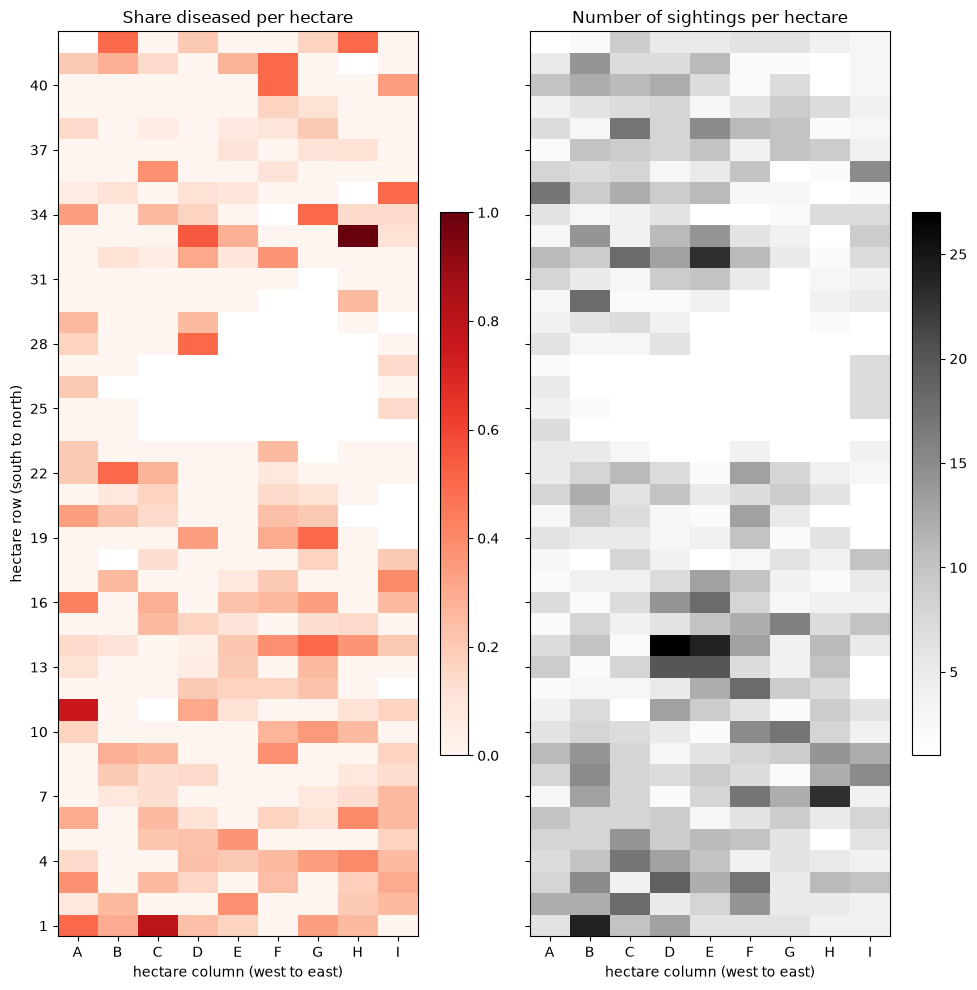

Hectares with sightings: 329 | median sightings per hectare: 7
Hectares where every sighting is diseased: 1, where none is: 167


In [10]:
# Same idea on the census grid: share diseased in each hectare (row 1-42 south to north, column A-I west to east)
hect = explore["Hectare"].astype("string").str.extract(r"^(\d+)([A-Z])$")
explore["hectare_row"] = pd.to_numeric(hect[0])
explore["hectare_col"] = hect[1]

cols = sorted(explore["hectare_col"].dropna().unique())
grid_rate = explore.pivot_table(index="hectare_row", columns="hectare_col", values=TARGET, aggfunc="mean").reindex(columns=cols)
grid_n = explore.pivot_table(index="hectare_row", columns="hectare_col", values=TARGET, aggfunc="size").reindex(columns=cols)

fig, axes = plt.subplots(1, 2, figsize=(10, 10), sharey=True)
im0 = axes[0].imshow(grid_rate.values, origin="lower", cmap="Reds", vmin=0, vmax=1, aspect="auto")
axes[0].set_title("Share diseased per hectare")
fig.colorbar(im0, ax=axes[0], shrink=0.6)
im1 = axes[1].imshow(grid_n.values, origin="lower", cmap="Greys", aspect="auto")
axes[1].set_title("Number of sightings per hectare")
fig.colorbar(im1, ax=axes[1], shrink=0.6)
for ax in axes:
    ax.set_xticks(range(len(cols)), cols)
    ax.set_xlabel("hectare column (west to east)")
axes[0].set_yticks(range(len(grid_rate.index))[::3], grid_rate.index[::3])
axes[0].set_ylabel("hectare row (south to north)")
plt.tight_layout()
plt.show()

hect_rates = rate_by(explore, "Hectare")
print(f"Hectares with sightings: {len(hect_rates)} | median sightings per hectare: {hect_rates['sightings'].median():.0f}")
print(f"Hectares where every sighting is diseased: {(hect_rates['share diseased'] == 1).sum()}, "
      f"where none is: {(hect_rates['share diseased'] == 0).sum()}")

### 4b. Over time

The census covers only 11 days in October 2018. If the disease is spreading, the share diseased might **rise over the days**. If it is flat, the date is probably not useful.

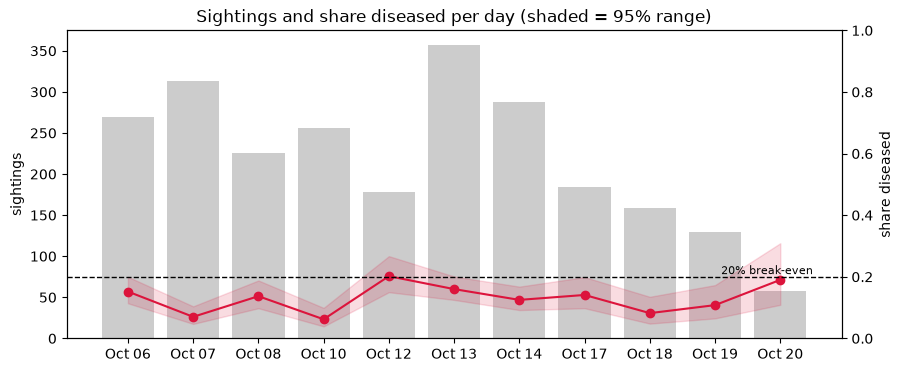

,sightings,diseased,share diseased,95% low,95% high,above 20%?
date,,,,,,
2018-10-06,269,41,0.152,0.114,0.200,unclear
2018-10-07,313,22,0.070,0.047,0.104,no
2018-10-08,226,31,0.137,0.098,0.188,no
2018-10-10,256,16,0.062,0.039,0.099,no
2018-10-12,178,36,0.202,0.150,0.267,unclear
2018-10-13,357,57,0.160,0.125,0.201,unclear
2018-10-14,288,36,0.125,0.092,0.168,no
2018-10-17,184,26,0.141,0.098,0.199,no
2018-10-18,159,13,0.082,0.048,0.135,no


In [11]:
by_day = rate_by(explore, "date").sort_index()
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(by_day.index.strftime("%b %d"), by_day["sightings"], color="0.8", label="sightings")
ax1.set_ylabel("sightings")
ax2 = ax1.twinx()
x = range(len(by_day))
ax2.plot(x, by_day["share diseased"], "o-", c="crimson", label="share diseased")
ax2.fill_between(x, by_day["95% low"], by_day["95% high"], color="crimson", alpha=0.15)
ax2.axhline(BREAK_EVEN_P, ls="--", c="k", lw=1)
ax2.text(len(by_day) - 0.5, BREAK_EVEN_P, " 20% break-even", va="bottom", ha="right", fontsize=8)
ax2.set_ylabel("share diseased")
ax2.set_ylim(0, 1)
ax1.set_title("Sightings and share diseased per day (shaded = 95% range)")
plt.show()
by_day

In [12]:
print(rate_by(explore, "Shift"), "\n")
if "cal_day_of_week" in explore:
    print(rate_by(explore, "cal_day_of_week").sort_index())

       sightings  diseased  share diseased  95% low  95% high above 20%?
Shift                                                                   
AM          1069       137           0.128    0.109     0.150         no
PM          1349       166           0.123    0.107     0.142         no 

                 sightings  diseased  share diseased  95% low  95% high above 20%?
cal_day_of_week                                                                   
0                      226        31           0.137    0.098     0.188         no
2                      440        42           0.095    0.071     0.127         no
3                      159        13           0.082    0.048     0.135         no
4                      308        50           0.162    0.125     0.208    unclear
5                      684       109           0.159    0.134     0.189         no
6                      601        58           0.097    0.075     0.123         no


### 4c. The squirrel itself: fur, age, where it was

These are re-checks of the Frame-step first look (which used **all** rows). Here we use the training set only, so a pattern found here may be used later.

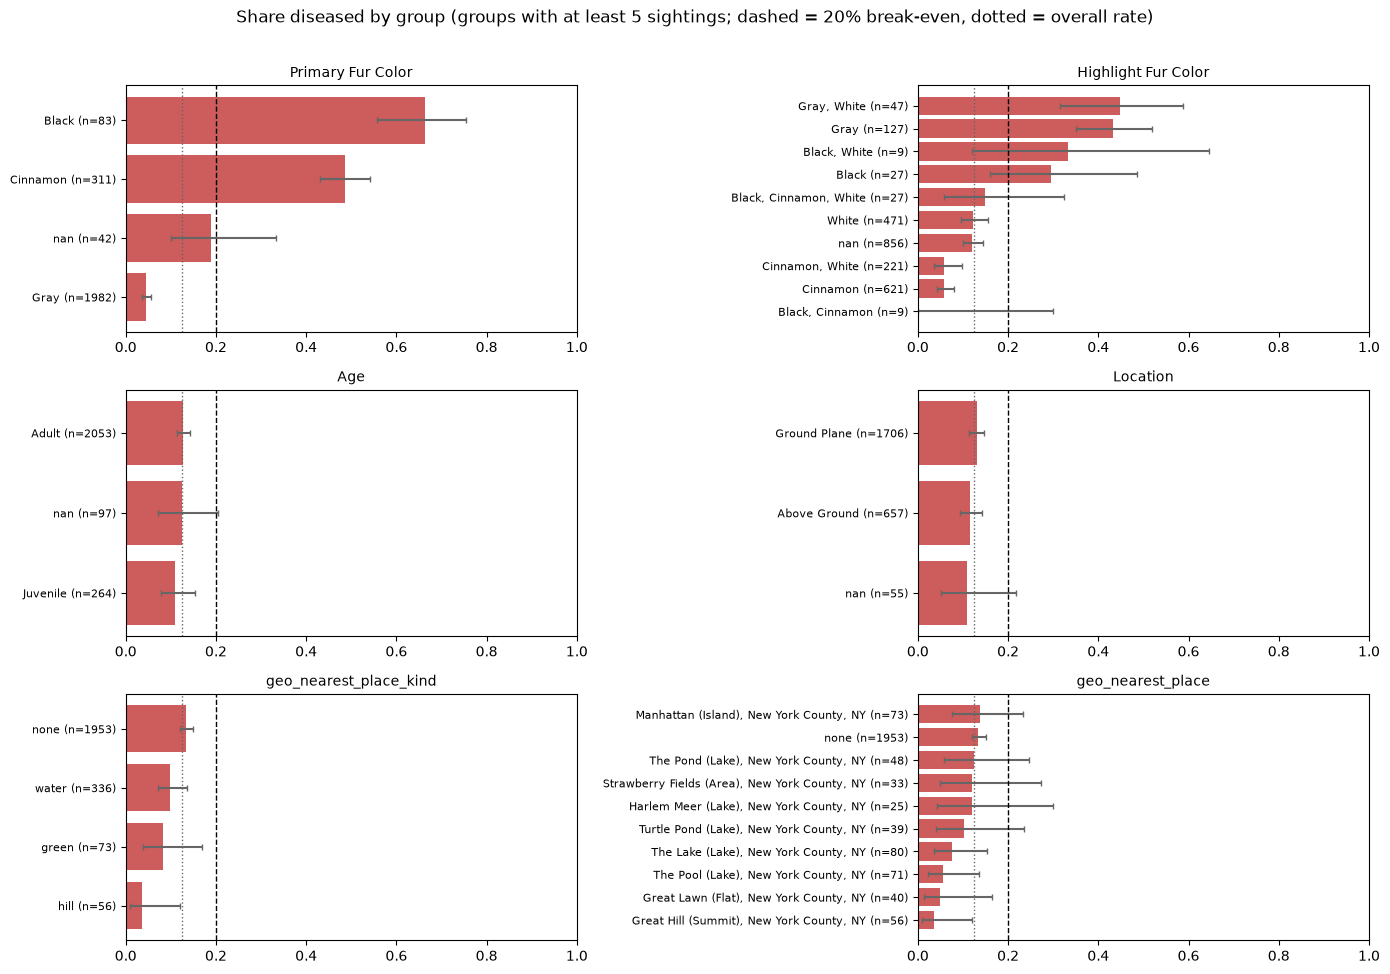

                   sightings  diseased  share diseased  95% low  95% high above 20%?
Primary Fur Color                                                                   
Black                     83        55           0.663    0.556     0.755        yes
Cinnamon                 311       151           0.486    0.430     0.541        yes
NaN                       42         8           0.190    0.100     0.333    unclear
Gray                    1982        89           0.045    0.037     0.055         no 

                        sightings  diseased  share diseased  95% low  95% high above 20%?
Highlight Fur Color                                                                      
Gray, White                    47        21           0.447    0.314     0.588        yes
Gray                          127        55           0.433    0.350     0.520        yes
Black, White                    9         3           0.333    0.121     0.646    unclear
Gray, Black                     3     

In [13]:
CAT_COLS = [c for c in ["Primary Fur Color", "Highlight Fur Color", "Age", "Location", "geo_nearest_place_kind",
                        "geo_nearest_place"] if c in explore]

fig, axes = plt.subplots(int(np.ceil(len(CAT_COLS) / 2)), 2, figsize=(14, 3.2 * int(np.ceil(len(CAT_COLS) / 2))))
for ax, c in zip(axes.flat, CAT_COLS):
    t = rate_by(explore, c, min_n=5).head(12).iloc[::-1]
    labels = [f"{i} (n={n})" for i, n in zip(t.index.astype(str), t["sightings"])]
    ax.barh(labels, t["share diseased"],
            xerr=[t["share diseased"] - t["95% low"], t["95% high"] - t["share diseased"]],
            color="indianred", ecolor="0.4", capsize=2)
    ax.axvline(BREAK_EVEN_P, ls="--", c="k", lw=1)
    ax.axvline(explore[TARGET].mean(), ls=":", c="0.4", lw=1)
    ax.set_xlim(0, 1)
    ax.set_title(c, fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.flat[len(CAT_COLS):]:
    ax.set_visible(False)
fig.suptitle("Share diseased by group (groups with at least 5 sightings; dashed = 20% break-even, dotted = overall rate)", y=1.01)
fig.tight_layout()
plt.show()

for c in CAT_COLS[:4]:
    print(rate_by(explore, c), "\n")

### 4d. Behavior

Each behavior is a True/False box ticked by the volunteer. The client notes say the main symptom is **aggression**, but there is no "aggressive" column. `Approaches`, `Chasing` and the alarm signals (`Kuks`, `Quaas`, `Tail flags`, `Tail twitches`) are the closest things we have.

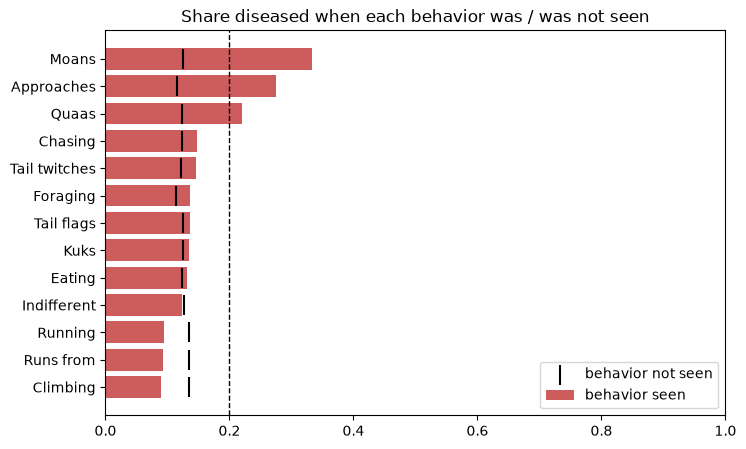

,sightings with it,share diseased WITH,95% range WITH,share diseased WITHOUT,verdict WITH (vs 20%),lift
behavior,,,,,,
Moans,3,0.333,0.06-0.79,0.125,unclear,2.66
Approaches,149,0.275,0.21-0.35,0.115,yes,2.39
Quaas,41,0.220,0.12-0.37,0.124,unclear,1.77
Chasing,218,0.147,0.11-0.20,0.123,no,1.20
Tail twitches,343,0.146,0.11-0.19,0.122,no,1.20
Foraging,1169,0.137,0.12-0.16,0.114,no,1.20
Tail flags,124,0.137,0.09-0.21,0.125,unclear,1.10
Kuks,89,0.135,0.08-0.22,0.125,unclear,1.08
Eating,609,0.131,0.11-0.16,0.123,no,1.07


             sightings  diseased  share diseased  95% low  95% high above 20%?
n_behaviors                                                                   
0                   46         8           0.174    0.091     0.307    unclear
1                  411        51           0.124    0.096     0.159         no
2                 1104       134           0.121    0.103     0.142         no
3                  586        77           0.131    0.106     0.161         no
4                  197        23           0.117    0.079     0.169         no
5                   60         6           0.100    0.047     0.201    unclear
6                   12         3           0.250    0.089     0.532    unclear
7                    1         0           0.000    0.000     0.793    unclear
8                    1         1           1.000    0.207     1.000        yes


In [14]:
rows = []
for c in BEHAVIORS:
    t = rate_by(explore, c)
    on = t.loc[True] if True in t.index else None
    off = t.loc[False] if False in t.index else None
    rows.append({"behavior": c,
                 "sightings with it": int(on["sightings"]) if on is not None else 0,
                 "share diseased WITH": on["share diseased"] if on is not None else np.nan,
                 "95% range WITH": f"{on['95% low']:.2f}-{on['95% high']:.2f}" if on is not None else "",
                 "share diseased WITHOUT": off["share diseased"] if off is not None else np.nan,
                 "verdict WITH (vs 20%)": on["above 20%?"] if on is not None else ""})
behav = pd.DataFrame(rows).set_index("behavior")
behav["lift"] = (behav["share diseased WITH"] / behav["share diseased WITHOUT"]).round(2)
behav = behav.sort_values("share diseased WITH", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
b = behav.iloc[::-1]
ax.barh(b.index, b["share diseased WITH"], color="indianred", label="behavior seen")
ax.scatter(b["share diseased WITHOUT"], b.index, c="k", marker="|", s=200, label="behavior not seen")
ax.axvline(BREAK_EVEN_P, ls="--", c="k", lw=1)
ax.set_xlim(0, 1)
ax.set_title("Share diseased when each behavior was / was not seen")
ax.legend(loc="lower right")
plt.show()
display(behav)

# Number of behaviors ticked per sighting
explore["n_behaviors"] = explore[BEHAVIORS].sum(axis=1)
print(rate_by(explore, "n_behaviors").sort_index())

### 4e. External data: place and weather

Distances to named places and the daily weather, split by label. If the two histograms in a panel look alike, that column probably does not help.

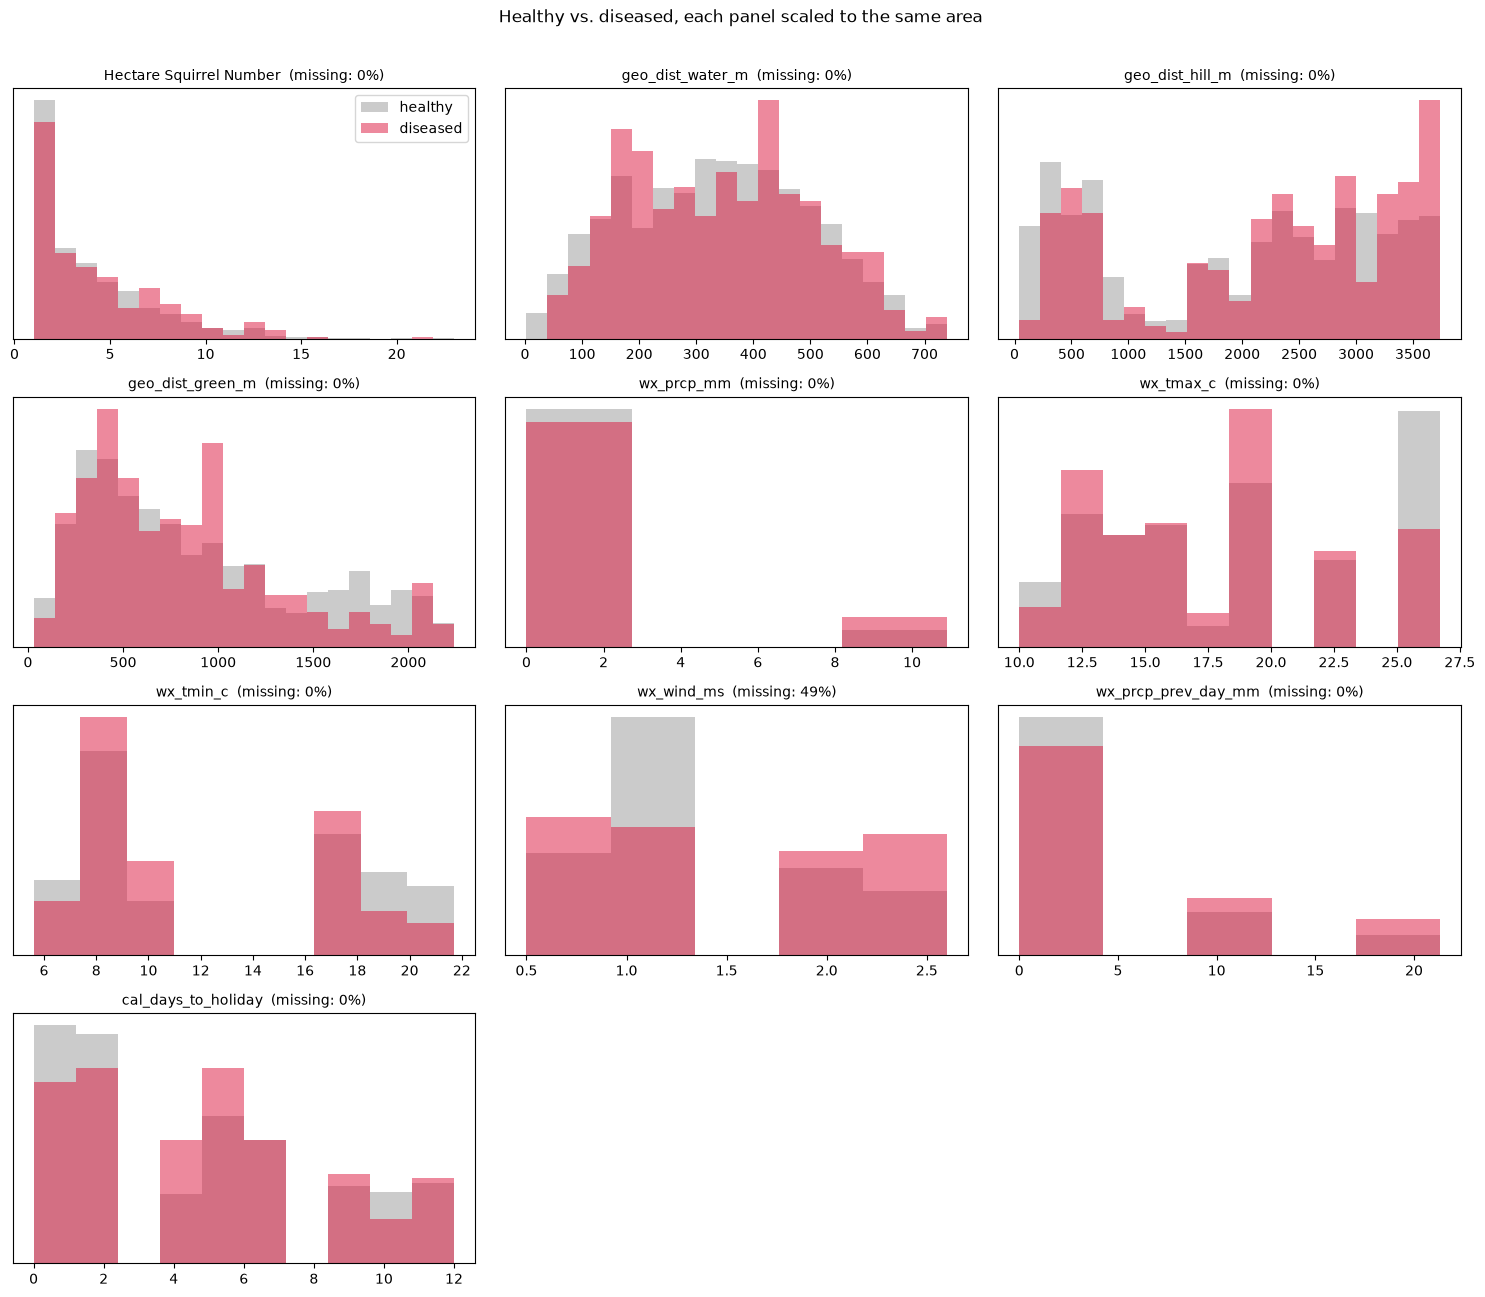

            wx_prcp_mm  wx_tmax_c  wx_tmin_c  wx_wind_ms  wx_prcp_prev_day_mm  diseased
date                                                                                   
2018-10-06         0.0       20.0       17.2         0.5                  0.0      0.15
2018-10-07         0.0       26.1       19.4         1.1                  0.0      0.07
2018-10-08         0.0       23.3       17.8         1.8                  0.0      0.14
2018-10-10         0.0       26.7       21.7         1.2                  0.0      0.06
2018-10-12        10.9       20.0       10.6         2.6                 21.3      0.20
2018-10-13         2.5       12.8        7.8         NaN                 10.9      0.16
2018-10-14         0.0       14.4        8.3         NaN                  2.5      0.12
2018-10-17         0.0       16.1        7.8         NaN                  0.3      0.14
2018-10-18         0.0       10.0        5.6         NaN                  0.0      0.08
2018-10-19         0.0       15.

In [15]:
EXT_NUM = [c for c in explore if c.startswith(("geo_dist_", "wx_")) or c in ("cal_days_to_holiday", "Hectare Squirrel Number")]
fig, axes = plt.subplots(int(np.ceil(len(EXT_NUM) / 3)), 3, figsize=(15, 3.2 * int(np.ceil(len(EXT_NUM) / 3))))
for ax, c in zip(axes.flat, EXT_NUM):
    vals = explore[c].dropna()
    bins = np.histogram_bin_edges(vals, bins=20 if vals.nunique() > 20 else max(vals.nunique(), 2))
    for lab, color in [(False, "0.6"), (True, "crimson")]:
        ax.hist(explore.loc[explore[TARGET] == lab, c].dropna(), bins=bins, density=True, alpha=0.5, color=color,
                label="diseased" if lab else "healthy")
    ax.set_title(f"{c}  (missing: {explore[c].isna().mean():.0%})", fontsize=10)
    ax.set_yticks([])
axes.flat[0].legend()
for ax in axes.flat[len(EXT_NUM):]:
    ax.set_visible(False)
fig.suptitle("Healthy vs. diseased, each panel scaled to the same area", y=1.01)
fig.tight_layout()
plt.show()

# Weather is one value per day, so it can only be judged at the day level (11 points)
wx_cols = [c for c in explore if c.startswith("wx_")]
print(explore.groupby("date")[wx_cols + [TARGET]].mean().round(2))

## 5. Study the correlations between attributes

Three views:
1. **Correlation with the target** for numeric and True/False columns. For a True/False target this is the point-biserial correlation, which only sees **straight-line** relationships.
2. **Mutual information** for every candidate feature, including categorical ones. It also picks up relationships that are **not** straight lines. 0 means no information; higher is better. The values are only useful to **rank** columns against each other.
3. **Correlations between features**, to find columns that repeat each other.

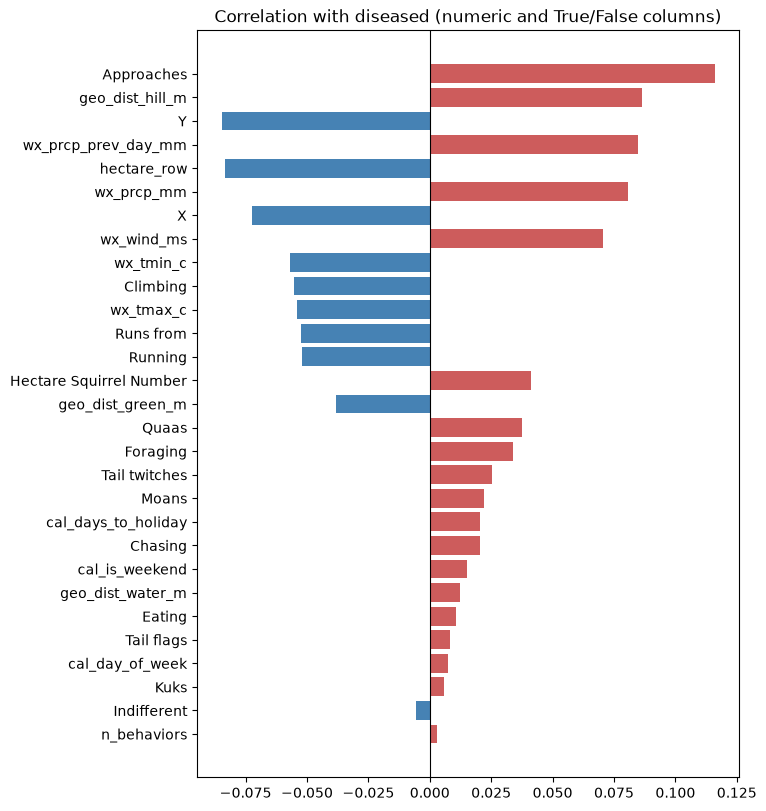

,corr with diseased
Approaches,0.116
geo_dist_hill_m,0.086
Y,-0.085
wx_prcp_prev_day_mm,0.085
hectare_row,-0.083
wx_prcp_mm,0.081
X,-0.072
wx_wind_ms,0.071
wx_tmin_c,-0.057
Climbing,-0.055


In [16]:
FEATURES = [c for c in explore if role_of(c).startswith("feature") and c != "date"]
numlike = [c for c in FEATURES if pd.api.types.is_numeric_dtype(explore[c]) or pd.api.types.is_bool_dtype(explore[c])]

with np.errstate(invalid="ignore", divide="ignore"):    # a column with one single value has no correlation
    corr_target = explore[numlike].astype(float).corrwith(explore[TARGET].astype(float)).dropna()
corr_target = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(7, 0.3 * len(corr_target) + 1))
c = corr_target.iloc[::-1]
ax.barh(c.index, c.values, color=np.where(c.values > 0, "indianred", "steelblue"))
ax.axvline(0, c="k", lw=0.8)
ax.set_title("Correlation with diseased (numeric and True/False columns)")
plt.show()
corr_target.round(3).to_frame("corr with diseased")

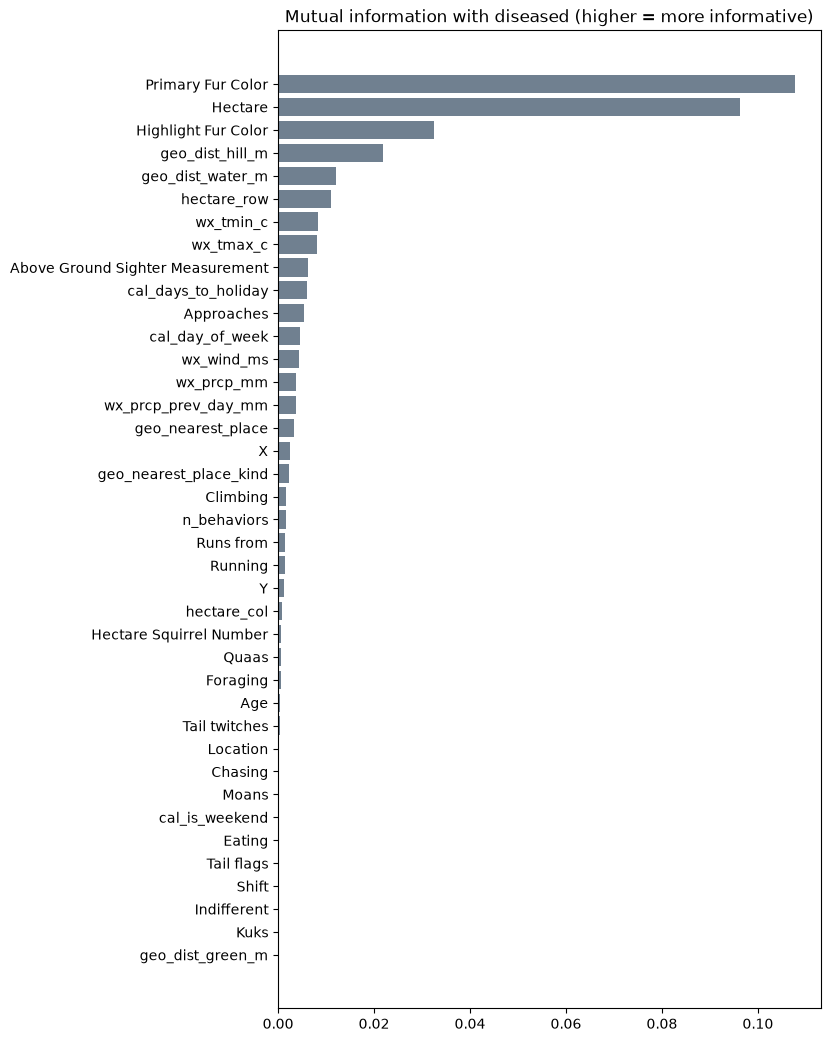

,mutual information
Primary Fur Color,0.1077
Hectare,0.0962
Highlight Fur Color,0.0325
geo_dist_hill_m,0.0219
geo_dist_water_m,0.0120
hectare_row,0.0110
wx_tmin_c,0.0084
wx_tmax_c,0.0081
Above Ground Sighter Measurement,0.0061
cal_days_to_holiday,0.0061


In [17]:
# Mutual information: categorical columns are turned into integer codes, missing values get their own code
mi_frame = pd.DataFrame(index=explore.index)
discrete = []
for col in FEATURES:
    s = explore[col]
    if pd.api.types.is_bool_dtype(s):
        mi_frame[col] = s.astype(int); discrete.append(True)
    elif pd.api.types.is_numeric_dtype(s):
        mi_frame[col] = s.fillna(s.median()); discrete.append(s.nunique() <= 15)
    else:
        mi_frame[col] = s.astype("string").fillna("(missing)").astype("category").cat.codes; discrete.append(True)

with warnings.catch_warnings():                 # sklearn warns about mixing continuous and discrete columns
    warnings.simplefilter("ignore")
    mi_values = mutual_info_classif(mi_frame, explore[TARGET], discrete_features=np.array(discrete), random_state=SEED)
mi = pd.Series(mi_values, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 0.3 * len(mi) + 1))
ax.barh(mi.index[::-1], mi.values[::-1], color="slategray")
ax.set_title("Mutual information with diseased (higher = more informative)")
plt.show()
mi.round(4).to_frame("mutual information")

**Caution on `Hectare` and other columns with many values.** Mutual information is biased upward for columns with many categories (`Hectare` has over 300). With only a few sightings per hectare, a column like that can look informative just by chance. Treat a high score for `Hectare` or `geo_nearest_place` as a hint to check, not as proof. The map in 4a is the better guide.

Pairs of features with |correlation| >= 0.8:
       column A            column B   corr
              Y         hectare_row  0.994
              Y     geo_dist_hill_m -0.992
geo_dist_hill_m         hectare_row -0.992
              X         hectare_row  0.946
      wx_tmax_c           wx_tmin_c  0.944
     wx_prcp_mm wx_prcp_prev_day_mm  0.935
              X     geo_dist_hill_m -0.922
              X                   Y  0.908
cal_day_of_week      cal_is_weekend  0.841
      wx_tmin_c cal_days_to_holiday -0.837


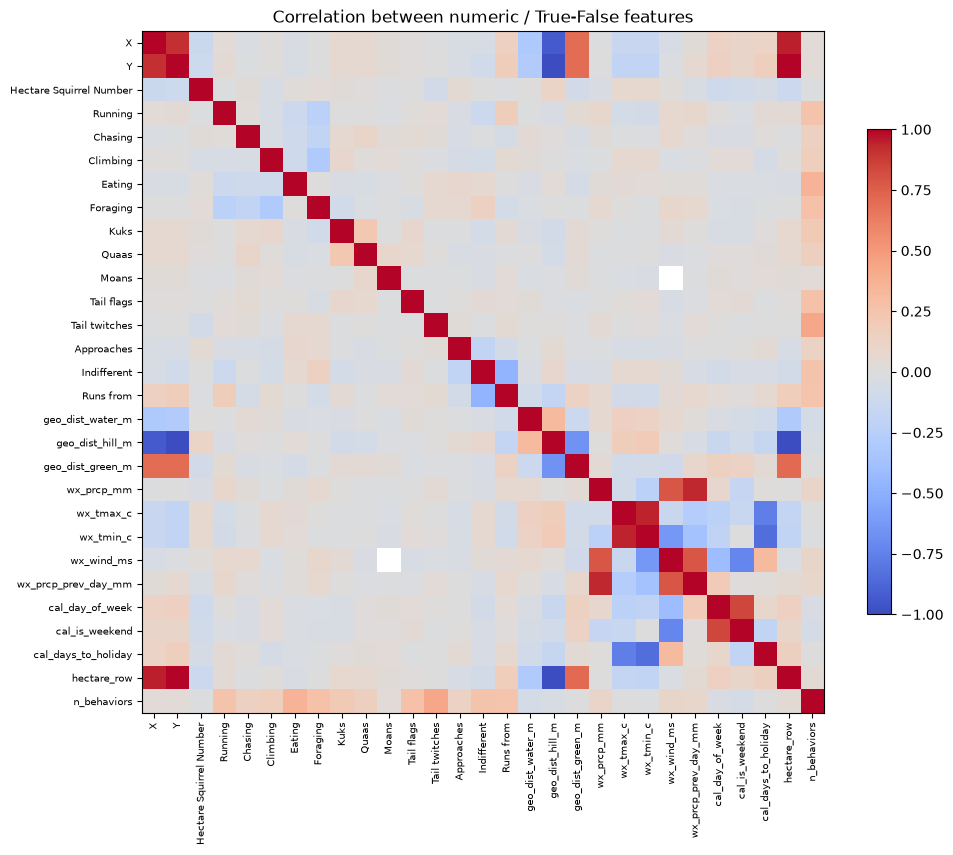

In [18]:
# Features that repeat each other (|correlation| >= 0.8)
with np.errstate(invalid="ignore", divide="ignore"):
    fcorr = explore[numlike].astype(float).corr()
pairs = (fcorr.where(np.triu(np.ones(fcorr.shape, bool), k=1)).stack().rename("corr").reset_index()
         .rename(columns={"level_0": "column A", "level_1": "column B"}))
pairs = pairs[pairs["corr"].abs() >= 0.8].sort_values("corr", key=abs, ascending=False)
print("Pairs of features with |correlation| >= 0.8:")
print(pairs.round(3).to_string(index=False) if len(pairs) else "none")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(fcorr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(fcorr)), fcorr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(fcorr)), fcorr.columns, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("Correlation between numeric / True-False features")
plt.show()

### Combinations: fur color together with behavior

A single column can hide a pattern that shows up in combination, or a strong column can explain away a weaker one. Example: if black and cinnamon squirrels approach people more often, `Approaches` might only look useful because of fur color.

In [19]:
if {"Primary Fur Color", "Approaches"} <= set(explore):
    combo = explore.groupby(["Primary Fur Color", "Approaches"], dropna=False)[TARGET].agg(sightings="size", diseased="sum")
    combo["share diseased"] = (combo["diseased"] / combo["sightings"]).round(3)
    print(combo, "\n")
    print("Share that approach, by fur color:")
    print(explore.groupby("Primary Fur Color", dropna=False)["Approaches"].mean().round(3))

                              sightings  diseased  share diseased
Primary Fur Color Approaches                                     
Black             False              77        49           0.636
                  True                6         6           1.000
Cinnamon          False             279       129           0.462
                  True               32        22           0.688
Gray              False            1872        76           0.041
                  True              110        13           0.118
NaN               False              41         8           0.195
                  True                1         0           0.000 

Share that approach, by fur color:
Primary Fur Color
Black       0.072
Cinnamon    0.103
Gray        0.055
NaN         0.024
Name: Approaches, dtype: float64


### Keywords in the free-text notes

The Frame step found that the symptom words in the client notes (aggression, foaming, mangy fur) are not columns, but the word *mad* appears in the free text. Here we check the symptom words, and then every word that appears in at least 5 notes, on the training set only.

In [20]:
TEXT_COLS = [c for c in ["Color notes", "Other Activities", "Other Interactions", "Specific Location"] if c in explore]
text = explore[TEXT_COLS].astype("string").fillna("").agg(" ".join, axis=1).str.lower()
print("Share of sightings with any free text:", f"{(text.str.strip() != '').mean():.0%}\n")

SYMPTOM_WORDS = ["mad", "aggress", "attack", "angry", "bite", "bit ", "chas", "fight", "foam", "drool", "mang", "bald",
                 "fur missing", "missing fur", "scab", "injur", "hurt", "limp", "sick", "hiss", "scream", "stare", "crazy"]
rows = []
for w in SYMPTOM_WORDS:
    has = text.str.contains(re.escape(w), regex=True)
    n = int(has.sum())
    if n:
        k = int(explore.loc[has, TARGET].sum())
        lo, hi = wilson(k, n)
        rows.append({"word (start)": w, "notes containing it": n, "diseased": k, "share diseased": round(k / n, 3),
                     "95% range": f"{float(lo):.2f}-{float(hi):.2f}"})
print("Symptom-like words:")
print(pd.DataFrame(rows).to_string(index=False) if rows else "none found", "\n")

# Every word used in >= 5 notes, ranked by share diseased
tokens = text.str.findall(r"[a-z]{3,}").apply(set)
word_counts = pd.Series([w for ws in tokens for w in ws]).value_counts()
common = word_counts[word_counts >= 5].index
word_rows = []
for w in common:
    has = tokens.apply(lambda ws: w in ws)
    k, n = int(explore.loc[has, TARGET].sum()), int(has.sum())
    lo, hi = wilson(k, n)
    word_rows.append({"word": w, "notes": n, "diseased": k, "share diseased": k / n, "95% low": float(lo)})
words = pd.DataFrame(word_rows).sort_values(["95% low", "notes"], ascending=False).round(3)
print("Words in at least 5 notes, sorted by the low end of their 95% range (most convincing first):")
words.head(20)

Share of sightings with any free text: 36%

Symptom-like words:
word (start)  notes containing it  diseased  share diseased 95% range
         mad                   44         3           0.068 0.02-0.18
        bit                     1         1           1.000 0.21-1.00
        chas                   52         9           0.173 0.09-0.30
       fight                    1         1           1.000 0.21-1.00
       stare                    6         1           0.167 0.03-0.56 

Words in at least 5 notes, sorted by the low end of their 95% range (most convincing first):


,word,notes,diseased,share diseased,95% low
12,tail,37,17,0.459,0.310
79,over,8,5,0.625,0.306
92,staring,7,4,0.571,0.250
44,approaches,15,7,0.467,0.248
116,tell,5,3,0.600,0.231
18,digging,26,10,0.385,0.224
82,front,8,4,0.500,0.215
49,was,14,6,0.429,0.214
15,fence,34,11,0.324,0.191
93,bench,6,3,0.500,0.188


## 6. Study how you would solve the problem manually

Suppose an animal-control dispatcher had to decide with simple rules, no model. We try a few rules a person could follow, and score each with the **total cost** from the Frame step on the training set.

**Important:** the fur-color rule is built from rates measured on these same rows, so its score is **optimistic**. These rules are a bar for the models to beat, not a final result. The hectare rule only looks at **earlier days**, like a dispatcher would, so it does not peek at the answer.

In [21]:
yv = explore[TARGET].to_numpy()
results = [rule_cost("Never send an agent", np.zeros(len(yv), bool), yv),
           rule_cost("Send to every sighting", np.ones(len(yv), bool), yv)]

if "Approaches" in explore:
    results.append(rule_cost("Send if it approaches", explore["Approaches"], yv))

if "Primary Fur Color" in explore:
    fur_rate = explore.groupby("Primary Fur Color")[TARGET].mean()
    risky_fur = fur_rate[fur_rate > BREAK_EVEN_P].index.tolist()
    send_fur = explore["Primary Fur Color"].isin(risky_fur)
    results.append(rule_cost(f"Send if fur is {' or '.join(risky_fur) or '(none above 20%)'}", send_fur, yv))
    if "Approaches" in explore:
        results.append(rule_cost("Send if that fur OR it approaches", send_fur | explore["Approaches"], yv))

# Dispatcher memory: send if a diseased squirrel was already found in this hectare on an EARLIER day
first_sick_day = explore[explore[TARGET]].groupby("Hectare")["date"].min()
earlier_sick = explore["date"] > explore["Hectare"].map(first_sick_day)
results.append(rule_cost("Send if this hectare had a diseased squirrel on an earlier day", earlier_sick.fillna(False), yv))
if "Primary Fur Color" in explore:
    results.append(rule_cost("Fur rule OR hectare had a diseased squirrel earlier", send_fur | earlier_sick.fillna(False), yv))

manual = pd.DataFrame(results).set_index("rule")
manual["saved vs. never send ($)"] = manual.loc["Never send an agent", "total cost ($)"] - manual["total cost ($)"]
manual.sort_values("total cost ($)")

,trips,diseased caught,diseased missed,precision,recall,total cost ($),saved vs. never send ($)
rule,,,,,,,
Send if fur is Black or Cinnamon,394,206,97,0.523,0.680,175800,127200
Send if that fur OR it approaches,505,219,84,0.434,0.723,185000,118000
Fur rule OR hectare had a diseased squirrel earlier,729,224,79,0.307,0.739,224800,78200
Send if it approaches,149,41,262,0.275,0.135,291800,11200
Never send an agent,0,0,303,NaN,0.000,303000,0
Send if this hectare had a diseased squirrel on an earlier day,403,58,245,0.144,0.191,325600,-22600
Send to every sighting,2418,303,0,0.125,1.000,483600,-180600


In [22]:
# How many trips each rule would need per day, vs. the 40-50 captures animal control can do
per_day = pd.DataFrame({"sightings": explore.groupby("date").size(),
                        "diseased": explore.groupby("date")[TARGET].sum()})
if "Primary Fur Color" in explore:
    per_day["trips, fur rule"] = send_fur.groupby(explore["date"]).sum()
per_day["trips, hectare rule"] = earlier_sick.fillna(False).groupby(explore["date"]).sum()
print("Note: this is the 80% training sample, so the full daily numbers are about 25% higher.")
per_day

Note: this is the 80% training sample, so the full daily numbers are about 25% higher.


,sightings,diseased,"trips, fur rule","trips, hectare rule"
date,,,,
2018-10-06,269,41,42,0
2018-10-07,313,22,50,11
2018-10-08,226,31,40,4
2018-10-10,256,16,45,36
2018-10-12,178,36,37,16
2018-10-13,357,57,67,66
2018-10-14,288,36,33,66
2018-10-17,184,26,33,65
2018-10-18,159,13,29,47


## 7. Identify the promising transformations you may want to apply

Candidates for the Preparation step. **Check each against the outputs above before keeping it**; the "keep if" column says what to look for.

| # | Transformation | Why | Keep if |
|---|---|---|---|
| 1 | **Drop** `Unique Squirrel ID`, `Lat/Long`, `Date`, `Combination of Primary and Highlight Color`, and the people-only `geo_` columns | Identifier, duplicates, or not meant for the model | Always (the Lat/Long check in section 2 should show 0 disagreements) |
| 2 | Split `Hectare` into **row number** (1–42) and **column letter** (A–I) | Turns 300+ categories into 2 location features a model can generalize from | The map/grid in 4a shows the disease in some zones more than others |
| 3 | **Neighborhood disease rate**: share diseased among nearby sightings | Disease likely spreads locally | 4a shows clustering. **Must be computed out-of-fold** (inside cross-validation), or it leaks the label |
| 4 | `Above Ground Sighter Measurement` → numeric height, `FALSE` → 0, plus a missing flag | Mixed text and numbers in one column | Height relates to the label in 4c/5 |
| 5 | `Highlight Fur Color` → one True/False column per color (multi-hot) | One cell can hold several colors | Any single highlight color has a clear rate in 4c |
| 6 | `Age` `?` → its own category "Unknown" (not dropped) | Unknown age may itself carry signal | `?` rate differs from the others |
| 7 | One-hot encode `Primary Fur Color`, `Location`, `Shift`, `geo_nearest_place_kind` | Categorical | — |
| 8 | **Keyword flags** from free text (e.g. `mad`, chasing words) | Closest thing to the "aggression" symptom | A word in section 5 has a 95% low end above the overall rate and appears in enough notes |
| 9 | `n_behaviors` and an **"alarm" count** (Kuks + Quaas + Moans + Tail flags + Tail twitches) | Summarizes agitation | Rates in 4d rise with the count |
| 10 | **Log** of distance columns (`geo_dist_*`) | Right-skewed distances | Section 2 shows strong right skew |
| 11 | Drop `wx_wind_ms` or impute it | About half of it is missing | It shows no relationship in 4e |
| 12 | Drop the weather and calendar columns entirely | Only 11 distinct days, so each is really a "which day" code | 4b/4e show no day-level pattern. Otherwise keep the strongest one only |
| 13 | Standardize numeric features | Needed for linear models, SVMs, neural nets | Always for those models |

**Leakage to watch for in Preparation:**
- Any feature built from the **label** (rates per hectare, per fur color, per word) must be fit **inside each cross-validation fold**, never on the full training set.
- The hectare rule in section 6 is safe only because it uses earlier days. A model feature built the same way must also use only earlier days.

## 8. Identify extra data that would be useful

| Data | Why it would help | Where it could come from |
|---|---|---|
| **Aggression / symptoms field** in the report (aggressive? foaming? mangy fur?) | These are the main symptoms in the client notes, and the census has none of them | Client: does the app record them? |
| **Which squirrels were tested** | Tells us whether "not in `diseased.csv`" means *healthy* or *never tested* | Client |
| **More days** of reports, especially after Oct 20 | 11 days is too few to learn anything about time or weather | Client / the app |
| **Exact time** of each report, not just AM/PM | Finer timing for spread between neighbors | Client / the app |
| **Earlier diseased captures with location** | Lets us build the "disease nearby recently" feature from real history | Client / animal control |
| **Tree cover, food sources, trash bins, feeding spots** in the park | Squirrels gather where food is, which could drive contact and spread | NYC Parks / NYC Open Data |
| **Other animal reports** (raccoons, dogs, rats) | The client worries about spread to other animals | NYC 311 / Parks |

If any of these are available, go back to **Get the Data**.

## 9. Document what you have learned

The cell below prints the main numbers from this notebook in one place. Write the findings under it after running.

In [23]:
summary = {}
summary["Training rows / diseased"] = f"{len(explore):,} / {int(explore[TARGET].sum())} ({explore[TARGET].mean():.1%})"
summary["Top 5 features by mutual information"] = ", ".join(mi.head(5).index)
summary["Top 5 by |correlation| with diseased"] = ", ".join(f"{k} ({v:+.2f})" for k, v in corr_target.head(5).items())
if "Primary Fur Color" in explore:
    fr = rate_by(explore, "Primary Fur Color")
    summary["Share diseased by fur color"] = ", ".join(f"{i}: {r['share diseased']:.0%} ({r['above 20%?']})" for i, r in fr.iterrows())
summary["Behaviors clearly above 20%"] = ", ".join(behav.index[behav["verdict WITH (vs 20%)"] == "yes"]) or "none"
summary["Cheapest manual rule"] = f"{manual['total cost ($)'].idxmin()}: ${manual['total cost ($)'].min():,.0f} " \
                                  f"(never send: ${manual.loc['Never send an agent', 'total cost ($)']:,.0f})"
summary["Hectares with sightings"] = f"{explore['Hectare'].nunique()}"
summary["Feature pairs with |corr| >= 0.8"] = f"{len(pairs)}"
for k, v in summary.items():
    print(f"{k:40s} {v}")

Training rows / diseased                 2,418 / 303 (12.5%)
Top 5 features by mutual information     Primary Fur Color, Hectare, Highlight Fur Color, geo_dist_hill_m, geo_dist_water_m
Top 5 by |correlation| with diseased     Approaches (+0.12), geo_dist_hill_m (+0.09), Y (-0.08), wx_prcp_prev_day_mm (+0.08), hectare_row (-0.08)
Share diseased by fur color              Black: 66% (yes), Cinnamon: 49% (yes), nan: 19% (unclear), Gray: 4% (no)
Behaviors clearly above 20%              Approaches
Cheapest manual rule                     Send if fur is Black or Cinnamon: $175,800 (never send: $303,000)
Hectares with sightings                  329
Feature pairs with |corr| >= 0.8         10


### Findings

*(Fill in after running. One line each, with the number that supports it.)*

1. **Location:**
2. **Fur color:**
3. **Behavior:**
4. **Free text:**
5. **Time and weather:**
6. **Data quality:**
7. **Best manual rule and its cost:**

### Questions for the field expert / client

The checklist suggests getting a field expert's view at this step. Add these to the single message to the client, together with the ones from the Get Data step:

1. Is there a biological reason black and cinnamon squirrels would be more affected, or could it be how the diseased squirrels were found (for example, agents looking for darker squirrels)?
2. Does the app ask the reporter whether the squirrel looked aggressive, foamed at the mouth or had patchy fur?
3. Were all captured squirrels tested, or only some?